# Naive Bayes With Three Examples

**Computational Social Science: Lecture 4 companion notebook**

This notebook builds Naive Bayes classifiers three times, at increasing scale:

| | Example | Data | Rows | Features | Point of the exercise |
|---|---|---|---|---|---|
| 1 | Weather & golf | from the lecture slides | 14 | 1 categorical | Verify that `sklearn` reproduces the hand calculation exactly |
| 2 | Voter turnout | from the lecture slides | 14 | 3 categorical | Where the *naive* independence assumption enters; the zero-frequency problem |
| 3 | Income & inequality | **real data** — 1994 US Census (UCI "Adult") | ~48,800 | 12 engineered | A full applied workflow: cleaning, evaluation, interpretation, and the model's limits |

Examples 1 and 2 are small enough that you can check every number against arithmetic you
did by hand. That is the whole reason they are here: once you trust that the library
computes what you think it computes, you can use it on data too large to check.

**A note on outputs.** The cells below have not been pre-run, so you will see no output
until you execute them. Run them in order (`Shift+Enter`), top to bottom. Example 3
downloads a dataset the first time it runs and needs an internet connection.

## 0. Setup

### Which Naive Bayes class should you use?

`sklearn.naive_bayes` has several variants. They differ *only* in the assumed shape of
$P(x_i \mid c)$ — the likelihood term. The prior, the multiplication, and the
normalization are identical in all of them.

| Class | Assumes each feature is | Use it for |
|---|---|---|
| `CategoricalNB` | an unordered category | survey responses, demographic codes, anything from a codebook |
| `GaussianNB` | continuous and normally distributed *within each class* | age, income, hours worked |
| `MultinomialNB` | a count | word counts in documents, event tallies |
| `BernoulliNB` | a binary present/absent indicator | word presence, yes/no checklists |

`CategoricalNB` is the one that matches the lecture's worked examples, so it is what we
use for Examples 1 and 2 and for the bulk of Example 3.

**A common mistake worth naming now**: 
* feeding integer-encoded categories (`0, 1, 2` for
`Overcast, Rainy, Sunny`) to `GaussianNB`.
* It runs without complaint and gives garbage,
because it treats those codes as measurements on a number line — implying that
"Rainy" sits halfway between "Overcast" and "Sunny".

In [1]:
import numpy as np
import pandas as pd

from sklearn.naive_bayes import CategoricalNB, GaussianNB
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, roc_auc_score,
                             confusion_matrix, classification_report)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline

import matplotlib.pyplot as plt

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 40)
np.set_printoptions(suppress=True, precision=4)

import sklearn
print("scikit-learn", sklearn.__version__)
print("pandas      ", pd.__version__)

scikit-learn 1.9.0
pandas       3.0.3


# Example 1: Weather and Golf

This is the dataset from slides 11–13. Fourteen days, one predictor (`Weather`), and a
binary outcome (`Play`). The lecture asks: **how likely are players to play if the
weather is sunny?** and answers 0.60 using Bayes' theorem.

Let's confirm that.

In [2]:
golf = pd.DataFrame({
    "Weather": ["Sunny", "Overcast", "Rainy", "Sunny", "Sunny", "Overcast", "Rainy",
                "Rainy", "Sunny", "Rainy", "Sunny", "Overcast", "Overcast", "Rainy"],
    "Play":    ["No", "Yes", "Yes", "Yes", "Yes", "Yes", "No",
                "No", "Yes", "Yes", "No", "Yes", "Yes", "No"],
})

print(f"{len(golf)} days")
golf

14 days


,Weather,Play
0,Sunny,No
1,Overcast,Yes
2,Rainy,Yes
3,Sunny,Yes
4,Sunny,Yes
5,Overcast,Yes
6,Rainy,No
7,Rainy,No
8,Sunny,Yes
9,Rainy,Yes


## 1.1 The frequency table

`pd.crosstab` is the counting step from the lecture — it *is* the frequency table on
slide 11. Nothing about Naive Bayes has happened yet; we are only tallying rows.

In [3]:
freq = pd.crosstab(golf["Weather"], golf["Play"], margins=True, margins_name="Total")
freq

Play,No,Yes,Total
Weather,,,
Overcast,0,4,4
Rainy,3,2,5
Sunny,2,3,5
Total,5,9,14


Compare this to slide 11: Overcast 0/4, Rainy 3/2, Sunny 2/3, grand total 5 No and 9 Yes.

Note the **0** in the Overcast/No cell. No overcast day was ever a no-play day in this
sample. We will come back to that in Example 2, because it is the single most common way
a hand-built Naive Bayes model breaks.

## 1.2 The likelihood table

Now divide by the **column** totals. This is the step students most often get backwards,
so it is worth saying slowly: we want $P(\text{Weather} \mid \text{Play})$. The class is
the *given*, so the class total is the denominator. `normalize="columns"` does exactly
this.

In [4]:
likelihood = pd.crosstab(golf["Weather"], golf["Play"], normalize="columns")
print(likelihood.round(3))

# The check: each COLUMN sums to 1, because each column is one conditional distribution.
# Rows do not sum to 1 -- a row mixes two different distributions.
print("\ncolumn sums:", likelihood.sum().round(3).to_dict())

prior = golf["Play"].value_counts(normalize=True)
print("\npriors:", prior.round(3).to_dict())

Play       No    Yes
Weather             
Overcast  0.0  0.444
Rainy     0.6  0.222
Sunny     0.4  0.333

column sums: {'No': 1.0, 'Yes': 1.0}

priors: {'Yes': 0.643, 'No': 0.357}


## 1.3 Bayes' theorem by hand

With one predictor we can apply the formula from slide 10 directly, because the
denominator $P(\text{Sunny})$ is just a row total sitting in the frequency table:

$$P(\text{Yes} \mid \text{Sunny}) = \frac{P(\text{Sunny} \mid \text{Yes}) \times P(\text{Yes})}{P(\text{Sunny})}$$

In [5]:
p_sunny_given_yes = 3 / 9      # from the likelihood table
p_yes             = 9 / 14     # prior
p_sunny           = 5 / 14     # row total: 5 of the 14 days were sunny

posterior_yes = p_sunny_given_yes * p_yes / p_sunny
posterior_no  = (2 / 5) * (5 / 14) / p_sunny

print(f"P(Yes | Sunny) = {posterior_yes:.4f}")
print(f"P(No  | Sunny) = {posterior_no:.4f}")
print(f"they sum to      {posterior_yes + posterior_no:.4f}")

# Sanity check against the raw data: of the 5 sunny days, how many were played?
sunny = golf[golf["Weather"] == "Sunny"]
print(f"\ndirect count: {(sunny['Play'] == 'Yes').sum()} of {len(sunny)} sunny days "
      f"were played = {(sunny['Play'] == 'Yes').mean():.4f}")

P(Yes | Sunny) = 0.6000
P(No  | Sunny) = 0.4000
they sum to      1.0000

direct count: 3 of 5 sunny days were played = 0.6000


0.60, matching the slide. And the direct count confirms it: 3 of the 5 sunny days were
play days. With a single predictor, Bayes' theorem is guaranteed to reproduce the simple
conditional proportion — it cannot do anything else. That makes this a good place to
verify your understanding, but it is also why this example does not yet show you what
Naive Bayes is *for*. That comes in Example 2.

## 1.4 The same thing in scikit-learn

`CategoricalNB` needs features as non-negative integers, not strings, so we encode first.
`OrdinalEncoder` maps each category to an integer. We pass `categories=` explicitly so
the mapping is stable and readable rather than whatever alphabetical order happens to
produce.

One subtlety that matters a lot: **`CategoricalNB` applies Laplace smoothing by default**
(`alpha=1.0`). The lecture's arithmetic uses raw counts, i.e. no smoothing. To reproduce
the slide exactly we set `alpha` to something negligible. In real work you would leave
the default on — Section 2.4 shows why.

In [6]:
WEATHER_CATS = ["Overcast", "Rainy", "Sunny"]

encoder = OrdinalEncoder(categories=[WEATHER_CATS])
X = pd.DataFrame(encoder.fit_transform(golf[["Weather"]]), columns=["Weather"])
y = (golf["Play"] == "Yes").astype(int)          # 1 = Yes, 0 = No

print("encoding:", dict(zip(WEATHER_CATS, range(3))))
print("X head:", X["Weather"].head(3).tolist(), " y head:", y.head(3).tolist())

# alpha ~ 0 reproduces the textbook (unsmoothed) arithmetic.
# force_alpha=True tells sklearn we really mean a tiny alpha and not to clip it upward.
nb_raw = CategoricalNB(alpha=1e-10, force_alpha=True).fit(X, y)

sunny_df = pd.DataFrame({"Weather": ["Sunny"]})
query = pd.DataFrame(encoder.transform(sunny_df), columns=["Weather"])
probs = nb_raw.predict_proba(query)[0]

print(f"\nsklearn:  P(No | Sunny) = {probs[0]:.4f}   P(Yes | Sunny) = {probs[1]:.4f}")
print(f"by hand:  P(No | Sunny) = {posterior_no:.4f}   P(Yes | Sunny) = {posterior_yes:.4f}")

encoding: {'Overcast': 0, 'Rainy': 1, 'Sunny': 2}
X head: [2.0, 0.0, 1.0]  y head: [0, 1, 1]

sklearn:  P(No | Sunny) = 0.4000   P(Yes | Sunny) = 0.6000
by hand:  P(No | Sunny) = 0.4000   P(Yes | Sunny) = 0.6000


Identical. Now let's open up the fitted model and confirm that the numbers stored inside
it are the two tables we built by hand.

In [7]:
# class_log_prior_ holds log P(c); feature_log_prob_ holds log P(x_i | c), one array
# per feature, shaped (n_classes, n_categories).
print("priors recovered from the model:")
print(pd.Series(np.exp(nb_raw.class_log_prior_), index=["No", "Yes"]).round(3))

print("\nlikelihood table recovered from the model:")
recovered = pd.DataFrame(np.exp(nb_raw.feature_log_prob_[0]),
                         index=["No", "Yes"], columns=WEATHER_CATS).T
print(recovered.round(3))

print("\nthe table we built with crosstab:")
print(likelihood.round(3))

priors recovered from the model:
No     0.357
Yes    0.643
dtype: float64

likelihood table recovered from the model:
           No    Yes
Overcast  0.0  0.444
Rainy     0.6  0.222
Sunny     0.4  0.333

the table we built with crosstab:
Play       No    Yes
Weather             
Overcast  0.0  0.444
Rainy     0.6  0.222
Sunny     0.4  0.333


The model *is* those tables. "Training" a Naive Bayes classifier is counting and
dividing — there is no optimizer, no gradient descent, no iteration. That is why it is
fast enough to be a sensible baseline on almost any dataset.

Notice `P(Overcast | No) = 0.000` in the recovered table. Ask `sklearn` to classify an
overcast day with smoothing switched off and see what happens:

In [8]:
overcast_df = pd.DataFrame({"Weather": ["Overcast"]})
overcast = pd.DataFrame(encoder.transform(overcast_df), columns=["Weather"])
print("unsmoothed, overcast:", nb_raw.predict_proba(overcast)[0].round(4))
print("-> the model claims 100% certainty from a single empty cell in 14 rows.")

nb_smoothed = CategoricalNB(alpha=1.0).fit(X, y)     # sklearn's default
print("\nwith Laplace smoothing (alpha=1):", nb_smoothed.predict_proba(overcast)[0].round(4))
print("P(Yes | Sunny) with smoothing:    ", nb_smoothed.predict_proba(query)[0].round(4))

unsmoothed, overcast: [0. 1.]
-> the model claims 100% certainty from a single empty cell in 14 rows.

with Laplace smoothing (alpha=1): [0.1429 0.8571]
P(Yes | Sunny) with smoothing:     [0.3846 0.6154]


Two things to take from that:

1. Smoothing turns the absurd 0.00/1.00 into something defensible.
2. It also shifts `P(Yes | Sunny)` slightly away from the slide's 0.60. The default
   `alpha=1.0` is the right choice for real work, but it means **`sklearn` will not
   reproduce textbook arithmetic unless you turn smoothing off**. If your hand
   calculation and your code disagree by a few percent, this is the first thing to check.

# Example 2 — Predicting Voter Turnout

Fourteen survey respondents, three predictors, one binary outcome. This is the second
worked example from the deck.

| Variable | Values | Role |
|---|---|---|
| `Age` | Young / Middle / Senior | predictor |
| `Contacted` | Yes / No — reached by a canvasser? | predictor |
| `Interest` | High / Low — self-reported interest in politics | predictor |
| `Vote` | **Yes / No** | class to predict |

Three predictors instead of one is what makes this example worth doing. With one
predictor, Bayes' theorem just recovers a conditional proportion. With three, the joint
$P(\text{Age}, \text{Contacted}, \text{Interest} \mid c)$ cannot be estimated from 14
rows — almost every three-way combination appears zero or one time — so we need the
independence assumption that gives the method its name.

In [9]:
voters = pd.DataFrame(
    [("Young",  "No",  "Low",  "No"),
     ("Young",  "No",  "High", "No"),
     ("Middle", "No",  "High", "Yes"),
     ("Senior", "No",  "Low",  "Yes"),
     ("Senior", "Yes", "High", "Yes"),
     ("Senior", "Yes", "High", "No"),
     ("Middle", "Yes", "High", "Yes"),
     ("Young",  "No",  "Low",  "No"),
     ("Young",  "Yes", "Low",  "Yes"),
     ("Senior", "No",  "High", "Yes"),
     ("Young",  "Yes", "Low",  "Yes"),
     ("Middle", "Yes", "Low",  "Yes"),
     ("Middle", "No",  "High", "Yes"),
     ("Senior", "No",  "Low",  "No")],
    columns=["Age", "Contacted", "Interest", "Vote"])

FEATURES = ["Age", "Contacted", "Interest"]
CATEGORIES = [["Young", "Middle", "Senior"], ["No", "Yes"], ["Low", "High"]]

print(voters["Vote"].value_counts().to_dict())
voters

{'Yes': 9, 'No': 5}


,Age,Contacted,Interest,Vote
0,Young,No,Low,No
1,Young,No,High,No
2,Middle,No,High,Yes
3,Senior,No,Low,Yes
4,Senior,Yes,High,Yes
5,Senior,Yes,High,No
6,Middle,Yes,High,Yes
7,Young,No,Low,No
8,Young,Yes,Low,Yes
9,Senior,No,High,Yes


## 2.1 One frequency table per predictor

This is the key structural consequence of the independence assumption: instead of one
big joint table over all three predictors (which would have 3 x 2 x 2 = 12 cells and
14 observations to fill them), we build three small marginal tables and never look at
the combinations at all.

In [10]:
for feature in FEATURES:
    print(pd.crosstab(voters[feature], voters["Vote"],
                      margins=True, margins_name="Total"), "\n")

Vote    No  Yes  Total
Age                   
Middle   0    4      4
Senior   2    3      5
Young    3    2      5
Total    5    9     14 

Vote       No  Yes  Total
Contacted                
No          4    4      8
Yes         1    5      6
Total       5    9     14 

Vote      No  Yes  Total
Interest                
High       2    5      7
Low        3    4      7
Total      5    9     14 



Every table has the same column totals (5 No, 9 Yes) and sums to 14. If yours doesn't,
you've miscounted.

The `Middle`/`No` cell is **0** — no middle-aged respondent in this sample failed to
vote. Hold that thought for Section 2.4.

## 2.2 Scoring a new case by hand

Our new respondent is **Senior**, **was contacted**, **High** interest.

Because $P(x)$ is identical for both classes, it cannot change which class scores
higher, so we drop it and compare unnormalized scores:

$$\text{score}(c) = P(c) \times P(\text{Age} \mid c) \times P(\text{Contacted} \mid c) \times P(\text{Interest} \mid c)$$

Then normalize by the sum of the two scores to get probabilities.

In [11]:
def nb_by_hand(data, features, values, target="Vote", verbose=True):
    '''Score every class of `target` for one observation, using raw (unsmoothed) counts.

    Returns a dict {class_label: posterior}. Deliberately written out longhand so each
    term is visible -- this is the arithmetic from the slides, not a clever vectorisation.
    '''
    n = len(data)
    scores = {}
    for label in sorted(data[target].unique()):
        subset = data[data[target] == label]
        prior = len(subset) / n
        score = prior
        terms = [f"P({label})={prior:.3f}"]
        for feature, value in zip(features, values):
            likelihood = (subset[feature] == value).sum() / len(subset)
            score *= likelihood
            terms.append(f"P({feature}={value}|{label})={likelihood:.3f}")
        scores[label] = score
        if verbose:
            print(f"  {' x '.join(terms)}  =  {score:.6f}")

    total = sum(scores.values())
    if total == 0:                      # every class scored exactly zero
        return {k: float("nan") for k in scores}
    return {k: v / total for k, v in scores.items()}


new_case = ["Senior", "Yes", "High"]
print("Scoring Age=Senior, Contacted=Yes, Interest=High")
posteriors = nb_by_hand(voters, FEATURES, new_case)
print("\nposteriors:", {k: round(v, 4) for k, v in posteriors.items()})

Scoring Age=Senior, Contacted=Yes, Interest=High
  P(No)=0.357 x P(Age=Senior|No)=0.400 x P(Contacted=Yes|No)=0.200 x P(Interest=High|No)=0.400  =  0.011429
  P(Yes)=0.643 x P(Age=Senior|Yes)=0.333 x P(Contacted=Yes|Yes)=0.556 x P(Interest=High|Yes)=0.556  =  0.066138

posteriors: {'No': np.float64(0.1473), 'Yes': np.float64(0.8527)}


Roughly 0.853 for Yes and 0.147 for No — the numbers from the slides. The prediction is
that this person votes, with about 85% confidence.

## 2.3 The same thing in scikit-learn

The encoding step now handles three columns at once. Everything else is unchanged.

In [12]:
encoder3 = OrdinalEncoder(categories=CATEGORIES)
X3 = pd.DataFrame(encoder3.fit_transform(voters[FEATURES]), columns=FEATURES)
y3 = (voters["Vote"] == "Yes").astype(int)

nb3_raw = CategoricalNB(alpha=1e-10, force_alpha=True).fit(X3, y3)

query3 = pd.DataFrame(encoder3.transform(pd.DataFrame([new_case], columns=FEATURES)),
                      columns=FEATURES)
probs3 = nb3_raw.predict_proba(query3)[0]

print(f"sklearn:  No {probs3[0]:.4f}   Yes {probs3[1]:.4f}")
print(f"by hand:  No {posteriors['No']:.4f}   Yes {posteriors['Yes']:.4f}")
print(f"\npredicted class: {'Yes' if nb3_raw.predict(query3)[0] == 1 else 'No'}")

sklearn:  No 0.1473   Yes 0.8527
by hand:  No 0.1473   Yes 0.8527

predicted class: Yes


### Which predictor actually drove the prediction?

A nice property of Naive Bayes is that the prediction decomposes into one factor per
predictor, so you can always say which feature did the work and by how much. The ratio
of the two likelihoods for a term tells you which way that term pushes: above 1 favours
Yes, below 1 favours No.

In [13]:
def contribution_table(model, encoder, features, values, class_names=("No", "Yes")):
    '''Break a prediction into its per-feature evidence ratios.'''
    rows = [{"term": "prior",
             class_names[0]: np.exp(model.class_log_prior_)[0],
             class_names[1]: np.exp(model.class_log_prior_)[1]}]
    codes = encoder.transform(pd.DataFrame([values], columns=features))[0].astype(int)
    for j, (feature, value) in enumerate(zip(features, values)):
        probs = np.exp(model.feature_log_prob_[j])[:, codes[j]]
        rows.append({"term": f"{feature} = {value}",
                     class_names[0]: probs[0], class_names[1]: probs[1]})
    table = pd.DataFrame(rows).set_index("term")
    table["ratio (Yes:No)"] = table[class_names[1]] / table[class_names[0]]
    return table


contrib = contribution_table(nb3_raw, encoder3, FEATURES, new_case)
print(contrib.round(3))
print("\nproduct of the ratios:", round(contrib["ratio (Yes:No)"].prod(), 3),
      "  <- the odds in favour of Yes")

                    No    Yes  ratio (Yes:No)
term                                         
prior            0.357  0.643           1.800
Age = Senior     0.400  0.333           0.833
Contacted = Yes  0.200  0.556           2.778
Interest = High  0.400  0.556           1.389

product of the ratios: 5.787   <- the odds in favour of Yes


Read the `ratio` column: being contacted is the strongest signal (about 2.8 to 1 toward
voting), high interest helps mildly, and being Senior actually leans *slightly against*
voting (ratio below 1) but is outweighed. Multiply the ratios together and you get the
final odds, which is just the same computation rearranged.

## 2.4 The zero-frequency problem, and Laplace smoothing

Now classify someone **Middle** aged, **not contacted**, with **Low** interest. The
`Middle`/`No` cell was empty, so $P(\text{Middle} \mid \text{No}) = 0$, and a single zero
annihilates the entire product for that class.

In [14]:
hard_case = ["Middle", "No", "Low"]
print("Scoring Age=Middle, Contacted=No, Interest=Low  (no smoothing)")
_ = nb_by_hand(voters, FEATURES, hard_case)

q_hard = pd.DataFrame(encoder3.transform(pd.DataFrame([hard_case], columns=FEATURES)),
                      columns=FEATURES)
print("\nsklearn, alpha~0: ", nb3_raw.predict_proba(q_hard)[0].round(4))
print("The model reports certainty. Note that the other two predictors both lean 'No'")
print("and neither was allowed to contribute -- the zero wiped them out.")

Scoring Age=Middle, Contacted=No, Interest=Low  (no smoothing)
  P(No)=0.357 x P(Age=Middle|No)=0.000 x P(Contacted=No|No)=0.800 x P(Interest=Low|No)=0.600  =  0.000000
  P(Yes)=0.643 x P(Age=Middle|Yes)=0.444 x P(Contacted=No|Yes)=0.444 x P(Interest=Low|Yes)=0.444  =  0.056437

sklearn, alpha~0:  [0. 1.]
The model reports certainty. Note that the other two predictors both lean 'No'
and neither was allowed to contribute -- the zero wiped them out.


Laplace (add-one) smoothing replaces each likelihood with

$$P(x_i \mid c) = \frac{\text{count} + \alpha}{n_c + \alpha k}$$

where $k$ is the number of categories that predictor has. `sklearn` handles the
per-feature $k$ for you.

In [15]:
nb3_smooth = CategoricalNB(alpha=1.0).fit(X3, y3)
print("alpha = 1.0:", nb3_smooth.predict_proba(q_hard)[0].round(4))
print("            -> 0.248 / 0.752, matching the smoothed arithmetic from the slides")

# What smoothing did to each Age likelihood. Note it barely moves the well-supported
# estimates but rescues the empty cell.
before = pd.DataFrame(np.exp(nb3_raw.feature_log_prob_[0]),
                      index=["No", "Yes"], columns=CATEGORIES[0]).T
after = pd.DataFrame(np.exp(nb3_smooth.feature_log_prob_[0]),
                     index=["No", "Yes"], columns=CATEGORIES[0]).T
print("\nP(Age | class), before and after smoothing:")
print(pd.concat({"alpha=0": before, "alpha=1": after}, axis=1).round(3))

alpha = 1.0: [0.2477 0.7523]
            -> 0.248 / 0.752, matching the smoothed arithmetic from the slides

P(Age | class), before and after smoothing:
       alpha=0        alpha=1       
            No    Yes      No    Yes
Young      0.6  0.222   0.500  0.250
Middle     0.0  0.444   0.125  0.417
Senior     0.4  0.333   0.375  0.333


# Example 3 — Income, Education and Inequality (1994 US Census)

Time for real data.

## The dataset

The **UCI "Adult" / Census Income** dataset is an extract of 48,842 records from the
1994 US Census Current Population Survey, assembled by Barry Becker and Ronny Kohavi.
UCI classifies it under *Social Science*, and it has been one of the most heavily used
datasets in both machine learning and algorithmic-fairness research for thirty years.

- Source: https://archive.ics.uci.edu/dataset/2/adult
- Citation: Becker, B. & Kohavi, R. (1996). *Adult*. UCI Machine Learning Repository.
  https://doi.org/10.24432/C5XW20 (CC BY 4.0)

**The classification task:** predict whether a person's annual income exceeds \$50,000
from demographic and employment characteristics — education, occupation, marital status,
hours worked, sex, race, age, and so on.

## Why this is a sociology problem and not just a coding exercise

The features are exactly the variables stratification research cares about. Fitting a
classifier here is a way of asking *how legible is the American income distribution from
demographic characteristics alone?* — and, just as interesting, *which characteristics
carry the most information, and for whom does the model fail?*

Three things to keep in view as we go:

1. **The \$50,000 threshold is arbitrary and dated.** In 1994 dollars it sat around the
   80th percentile of individual earnings. Dichotomising a continuous outcome throws away
   information, and where you put the cut determines what "high income" means.
2. **Prediction is not explanation.** A high evidence weight on `marital-status` does not
   mean marriage causes income. Selection into marriage, joint tax filing, and household
   composition are all tangled together in that one variable.
3. **The independence assumption will be badly violated here**, in ways we can measure.
   `education` and `education-num` encode the same thing twice; `marital-status` and
   `relationship` overlap heavily. Section 3.8 quantifies it.

## 3.1 Loading the data

The loader tries three sources in order, so it works whether or not you have a cached
copy: a local file, OpenML (via `sklearn`), and the UCI archive directly. It then
normalizes column names and missing-value codes, because the three sources encode them
differently — UCI uses a literal `?` for missing, OpenML uses real `NaN`s and names the
target column `class`.

**This cell needs an internet connection the first time.** After it succeeds it writes
`adult.csv` locally, so subsequent runs are offline.

In [16]:
from pathlib import Path

COLUMNS = ["age", "workclass", "fnlwgt", "education", "education-num", "marital-status",
           "occupation", "relationship", "race", "sex", "capital-gain", "capital-loss",
           "hours-per-week", "native-country", "income"]

UCI_URL = ("https://archive.ics.uci.edu/ml/machine-learning-databases/"
           "adult/adult.data")
LOCAL = Path("adult.csv")


def normalise(df):
    '''Make any of the three sources look the same: lowercase hyphenated column names,
    real NaNs for missing values, and an `income` column of '<=50K' / '>50K' strings.'''
    df = df.copy()
    df.columns = [str(c).strip().lower().replace("_", "-") for c in df.columns]
    for alias in ("class", "income-per-year", "target"):
        if alias in df.columns and "income" not in df.columns:
            df = df.rename(columns={alias: "income"})
    for c in df.columns:
        if not pd.api.types.is_numeric_dtype(df[c]):
            df[c] = (df[c].astype(str).str.strip()
                       .replace({"?": np.nan, "nan": np.nan,
                                 "None": np.nan, "<NA>": np.nan}))
    # the UCI test split appends a period to the label; 0/1 encodings also exist
    df["income"] = (df["income"].astype(str).str.strip().str.rstrip(".")
                      .replace({"1": ">50K", "0": "<=50K"}))
    return df


def load_adult():
    if LOCAL.exists():
        print(f"loading cached {LOCAL}")
        return normalise(pd.read_csv(LOCAL))

    try:
        from sklearn.datasets import fetch_openml
        print("fetching from OpenML (data_id=1590) ...")
        bunch = fetch_openml(data_id=1590, as_frame=True, parser="auto")
        df = bunch.frame
    except Exception as exc:
        print(f"OpenML failed ({type(exc).__name__}); falling back to the UCI archive ...")
        df = pd.read_csv(UCI_URL, header=None, names=COLUMNS,
                         skipinitialspace=True, na_values="?")

    df = normalise(df)
    df.to_csv(LOCAL, index=False)
    print(f"cached to {LOCAL}")
    return df


adult = load_adult()
print(f"\n{adult.shape[0]:,} rows x {adult.shape[1]} columns")
adult.head()

fetching from OpenML (data_id=1590) ...
cached to adult.csv

48,842 rows x 15 columns


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K


## 3.2 What are we looking at?

Always do this before modelling. Three questions: how imbalanced is the outcome, where
are the missing values, and does anything look wrong?

In [17]:
y = (adult["income"] == ">50K").astype(int)

print("outcome distribution")
print(adult["income"].value_counts())
print(f"\nbase rate: {y.mean():.4f} earn >50K")
print(f"-> a model that always guesses '<=50K' is {1 - y.mean():.1%} accurate.")
print("   Any model we build has to beat that, and accuracy alone will be a poor")
print("   summary of whether it has learned anything.\n")

missing = adult.isna().sum()
print("missing values:")
print(missing[missing > 0].to_string() if missing.any() else "  none")

outcome distribution
income
<=50K    37155
>50K     11687
Name: count, dtype: int64

base rate: 0.2393 earn >50K
-> a model that always guesses '<=50K' is 76.1% accurate.
   Any model we build has to beat that, and accuracy alone will be a poor
   summary of whether it has learned anything.

missing values:
workclass         2799
occupation        2809
native-country     857


In [18]:
# numeric summary
print(adult[["age", "hours-per-week", "capital-gain", "capital-loss",
             "education-num", "fnlwgt"]].describe().round(1))

# categorical cardinality
cat_cols = adult.select_dtypes(exclude="number").columns.drop("income")
print("\ndistinct values per categorical column:")
print(adult[cat_cols].nunique().sort_values(ascending=False).to_string())

           age  hours-per-week  capital-gain  capital-loss  education-num     fnlwgt
count  48842.0         48842.0       48842.0       48842.0        48842.0    48842.0
mean      38.6            40.4        1079.1          87.5           10.1   189664.1
std       13.7            12.4        7452.0         403.0            2.6   105604.0
min       17.0             1.0           0.0           0.0            1.0    12285.0
25%       28.0            40.0           0.0           0.0            9.0   117550.5
50%       37.0            40.0           0.0           0.0           10.0   178144.5
75%       48.0            45.0           0.0           0.0           12.0   237642.0
max       90.0            99.0       99999.0        4356.0           16.0  1490400.0

distinct values per categorical column:
native-country    41
education         16
occupation        14
workclass          8
marital-status     7
relationship       6
race               5
sex                2


Two columns need a decision before we go further, and both decisions are substantive
rather than technical:

- **`fnlwgt`** is the census *sampling weight* — how many people in the population each
  row represents. It is not a property of the person and must not be used as a predictor.
  (It should arguably be used to weight the analysis, which is a real limitation of how
  this dataset is usually modelled, including here.)
- **`education-num`** is a numeric recoding of `education`. Including both would feed the
  classifier the same information twice, and because Naive Bayes multiplies likelihoods,
  duplicated evidence gets counted twice over. We keep the readable categorical version.

## 3.3 Feature engineering

We are going to put everything through `CategoricalNB`, which means binning the
continuous variables. That is a real modelling choice with a trade-off:

- **Cost:** binning discards within-bin variation, and the bin edges are our invention.
- **Benefit:** it drops the normality assumption `GaussianNB` would impose. Age is
  roughly plausible as normal-within-class; `capital-gain` emphatically is not — it is
  zero for about 92% of people and enormous for a few. No Gaussian fits that, and
  pretending otherwise would corrupt every prediction involving it.

So `capital-gain` and `capital-loss` become simple yes/no indicators, which is also
closer to what they actually measure: whether a person holds income-generating assets.
Age and hours get substantively meaningful bands rather than equal-width ones.

In [19]:
d = adult.copy()

d["age_band"] = pd.cut(d["age"], bins=[16, 24, 34, 44, 54, 64, 200],
                       labels=["17-24", "25-34", "35-44", "45-54", "55-64", "65+"])

d["hours_band"] = pd.cut(d["hours-per-week"], bins=[0, 34, 44, 59, 200],
                         labels=["part-time (<35)", "full-time (35-44)",
                                 "long (45-59)", "very long (60+)"])

d["capital_gain"] = np.where(d["capital-gain"] > 0, "yes", "no")
d["capital_loss"] = np.where(d["capital-loss"] > 0, "yes", "no")

CAT = ["age_band", "hours_band", "capital_gain", "capital_loss", "workclass",
       "education", "marital-status", "occupation", "relationship", "race",
       "sex", "native-country"]
NUM = ["age", "capital-gain", "capital-loss", "hours-per-week"]   # for GaussianNB later

print("share of people with any capital gain:", round((d['capital-gain'] > 0).mean(), 4))
print("share with any capital loss:          ", round((d['capital-loss'] > 0).mean(), 4))
print("\nage bands:  ", d["age_band"].value_counts().sort_index().to_dict())
print("hours bands:", d["hours_band"].value_counts().sort_index().to_dict())

share of people with any capital gain: 0.0826
share with any capital loss:           0.0467

age bands:   {'17-24': 8432, '25-34': 12577, '35-44': 12193, '45-54': 8771, '55-64': 4782, '65+': 2087}
hours bands: {'part-time (<35)': 8395, 'full-time (35-44)': 27029, 'long (45-59)': 9565, 'very long (60+)': 3853}


### Handling missing values

`workclass`, `occupation` and `native-country` have missing entries. Rather than drop
those rows we make **"Missing" its own category**. For a categorical Naive Bayes this is
cheap and often better than imputation: if non-response is itself informative (and in
labour-force surveys it usually is), the model can learn from it. Dropping the rows would
throw the information away and bias the sample.

In [20]:
Xc = d[CAT].astype(object)
Xc = Xc.where(Xc.notna(), "Missing")

assert Xc.isna().sum().sum() == 0
print("'Missing' now appears as a category where relevant:")
for c in ["workclass", "occupation", "native-country"]:
    n_missing = (Xc[c] == "Missing").sum()
    print(f"  {c:16s} {n_missing:5d} rows ({n_missing / len(Xc):.2%})")

'Missing' now appears as a category where relevant:
  workclass         2799 rows (5.73%)
  occupation        2809 rows (5.75%)
  native-country     857 rows (1.75%)


### Encoding

`CategoricalNB` wants non-negative integers. We fit the `OrdinalEncoder` on the **full
column vocabulary** rather than on the training split alone.

Is that leakage? No — and the reason is worth being precise about. Leakage means letting
information about the *outcome* reach the model. Here we are only telling the encoder
which category labels exist, which is information from the census codebook, not from
anyone's income. If you were deploying this model you would take the vocabulary from the
codebook. What you must *not* do is compute anything outcome-dependent (class counts,
likelihoods, target encodings) outside the training fold.

In [21]:
VOCAB = [sorted(Xc[c].unique().tolist()) for c in CAT]
encoder_adult = OrdinalEncoder(categories=VOCAB).fit(Xc)

X = pd.DataFrame(encoder_adult.transform(Xc), columns=CAT, index=Xc.index)

print("categories per feature:")
for name, vocab in zip(CAT, VOCAB):
    print(f"  {name:16s} {len(vocab):2d}")
print(f"\nencoded shape: {X.shape}")
X.head(3)

categories per feature:
  age_band          6
  hours_band        4
  capital_gain      2
  capital_loss      2
  workclass         9
  education        16
  marital-status    7
  occupation       15
  relationship      6
  race              5
  sex               2
  native-country   42

encoded shape: (48842, 12)


,age_band,hours_band,capital_gain,capital_loss,workclass,education,marital-status,occupation,relationship,race,sex,native-country
0,1.0,0.0,0.0,0.0,4.0,1.0,4.0,6.0,3.0,2.0,1.0,39.0
1,2.0,1.0,0.0,0.0,4.0,11.0,2.0,4.0,0.0,4.0,1.0,39.0
2,1.0,0.0,0.0,0.0,1.0,7.0,2.0,11.0,0.0,4.0,1.0,39.0


## 3.4 Train/test split

`stratify=y` keeps the 24/76 class balance identical in both splits. With imbalanced
data this matters: an unstratified split can hand you a test set with a noticeably
different base rate, which makes the metrics hard to interpret.

In [22]:
idx_train, idx_test = train_test_split(
    np.arange(len(d)), test_size=0.25, stratify=y, random_state=42)

X_train, X_test = X.iloc[idx_train], X.iloc[idx_test]
y_train, y_test = y.iloc[idx_train], y.iloc[idx_test]

print(f"train {len(X_train):,}   test {len(X_test):,}")
print(f"base rate  train {y_train.mean():.4f}   test {y_test.mean():.4f}")

train 36,631   test 12,211
base rate  train 0.2393   test 0.2393


## 3.5 Fit, and compare against honest baselines

A model's accuracy means nothing in isolation. We need at least two reference points:

- **`DummyClassifier`** — always predicts the majority class. This is the floor. On a
  76/24 split it scores about 0.76, which looks respectable and has learned nothing.
- **`LogisticRegression`** — a model of comparable simplicity that does *not* assume
  feature independence. If Naive Bayes lands far below it, the independence assumption is
  costing us; if it lands close, the assumption is doing little harm here.

In [23]:
nb_adult = CategoricalNB(alpha=1.0).fit(X_train, y_train)

pred_nb = nb_adult.predict(X_test)
prob_nb = nb_adult.predict_proba(X_test)[:, 1]

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

logreg = make_pipeline(
    ColumnTransformer([("num", StandardScaler(), NUM),
                       ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)]),
    LogisticRegression(max_iter=5000))
logreg.fit(d.iloc[idx_train][NUM + CAT], y_train)
prob_lr = logreg.predict_proba(d.iloc[idx_test][NUM + CAT])[:, 1]

results = pd.DataFrame([
    {"model": "majority baseline",
     "accuracy": accuracy_score(y_test, dummy.predict(X_test)),
     "balanced acc": balanced_accuracy_score(y_test, dummy.predict(X_test)),
     "ROC AUC": np.nan},
    {"model": "CategoricalNB",
     "accuracy": accuracy_score(y_test, pred_nb),
     "balanced acc": balanced_accuracy_score(y_test, pred_nb),
     "ROC AUC": roc_auc_score(y_test, prob_nb)},
    {"model": "LogisticRegression",
     "accuracy": accuracy_score(y_test, logreg.predict(d.iloc[idx_test][NUM + CAT])),
     "balanced acc": balanced_accuracy_score(
         y_test, logreg.predict(d.iloc[idx_test][NUM + CAT])),
     "ROC AUC": roc_auc_score(y_test, prob_lr)},
]).set_index("model")

print(results.round(4))

                    accuracy  balanced acc  ROC AUC
model                                              
majority baseline     0.7607        0.5000      NaN
CategoricalNB         0.8104        0.7975   0.8902
LogisticRegression    0.8598        0.7728   0.9137


**Reading this table.** Look at `balanced acc` and `ROC AUC` rather than `accuracy`. The
majority baseline gets a high accuracy and a balanced accuracy of exactly 0.50 — it is
right about everyone who earns less and wrong about everyone who earns more. Balanced
accuracy averages the per-class recall, so it exposes that immediately. AUC asks a
different and often more useful question: if you draw one high earner and one low earner
at random, how often does the model score the high earner higher?

In [24]:
cm = confusion_matrix(y_test, pred_nb)
print(pd.DataFrame(cm,
                   index=["actual <=50K", "actual >50K"],
                   columns=["predicted <=50K", "predicted >50K"]))
print()
print(classification_report(y_test, pred_nb,
                            target_names=["<=50K", ">50K"], digits=3))

              predicted <=50K  predicted >50K
actual <=50K             7638            1651
actual >50K               664            2258

              precision    recall  f1-score   support

       <=50K      0.920     0.822     0.868      9289
        >50K      0.578     0.773     0.661      2922

    accuracy                          0.810     12211
   macro avg      0.749     0.798     0.765     12211
weighted avg      0.838     0.810     0.819     12211



Pay attention to the gap between precision and recall on the `>50K` row. Which one matters
depends entirely on the application — and that is a substantive question, not a technical
one. If this model were screening people for a benefits programme, a false negative
(missing someone who needs help) and a false positive (enrolling someone who doesn't)
carry very different human costs, and no single number captures that trade-off.

In [26]:
# Cross-validation, so we are not reading tea leaves from one arbitrary split.
cv = cross_val_score(CategoricalNB(alpha=1.0), X, y,
                     cv=StratifiedKFold(5, shuffle=True, random_state=0),
                     scoring="roc_auc")
print("5-fold AUC:", cv.round(4))
print(f"mean {cv.mean():.4f}  sd {cv.std():.4f}")

5-fold AUC: [0.8933 0.8927 0.8883 0.8852 0.8889]
mean 0.8897  sd 0.0030


## 3.6 Two other ways to handle the continuous variables

Our binning decision was one of three reasonable options. Let's measure the other two
rather than assert that ours was best.

**`GaussianNB` on the raw numerics.** Assumes each is normal within each class. For `age`
and `hours-per-week` that is defensible; for `capital-gain` it is not.

**A mixed model.** Use `CategoricalNB` for the categorical features and `GaussianNB` for
the continuous ones, and combine them. This is legitimate because Naive Bayes already
treats features as independent — the joint log-likelihood is just a sum, so we can sum
across two models. The one trap: both models include the prior, so adding their
log-posteriors double-counts it and we must subtract one copy back out.

In [27]:
gnb = GaussianNB().fit(d.iloc[idx_train][NUM], y_train)
prob_gnb = gnb.predict_proba(d.iloc[idx_test][NUM])[:, 1]

# --- mixed model: sum the log-posteriors, subtract the duplicated log-prior ---
log_post_cat = nb_adult.predict_log_proba(X_test)
log_post_num = gnb.predict_log_proba(d.iloc[idx_test][NUM])
log_prior = np.log(np.bincount(y_train) / len(y_train))

joint = log_post_cat + log_post_num - log_prior
joint -= joint.max(axis=1, keepdims=True)      # subtract the row max for numerical safety
prob_mixed = np.exp(joint)[:, 1] / np.exp(joint).sum(axis=1)

comparison = pd.DataFrame([
    {"approach": "CategoricalNB (binned numerics)", "ROC AUC": roc_auc_score(y_test, prob_nb)},
    {"approach": "GaussianNB (raw numerics only)",  "ROC AUC": roc_auc_score(y_test, prob_gnb)},
    {"approach": "mixed: Categorical + Gaussian",   "ROC AUC": roc_auc_score(y_test, prob_mixed)},
    {"approach": "LogisticRegression (reference)",  "ROC AUC": roc_auc_score(y_test, prob_lr)},
]).set_index("approach")
print(comparison.round(4))

                                 ROC AUC
approach                                
CategoricalNB (binned numerics)   0.8902
GaussianNB (raw numerics only)    0.7941
mixed: Categorical + Gaussian     0.8885
LogisticRegression (reference)    0.9137


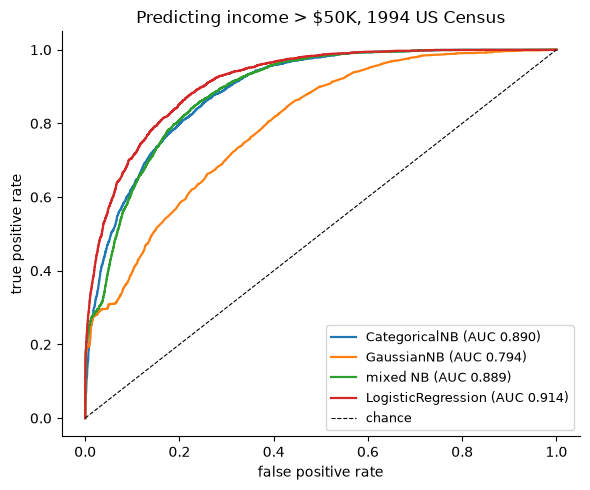

In [28]:
fig, ax = plt.subplots(figsize=(6, 5))
from sklearn.metrics import roc_curve

for label, probs in [("CategoricalNB", prob_nb), ("GaussianNB", prob_gnb),
                     ("mixed NB", prob_mixed), ("LogisticRegression", prob_lr)]:
    fpr, tpr, _ = roc_curve(y_test, probs)
    ax.plot(fpr, tpr, lw=1.6, label=f"{label} (AUC {roc_auc_score(y_test, probs):.3f})")

ax.plot([0, 1], [0, 1], "k--", lw=0.8, label="chance")
ax.set_xlabel("false positive rate")
ax.set_ylabel("true positive rate")
ax.set_title("Predicting income > $50K, 1994 US Census")
ax.legend(loc="lower right", fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 3.7 Interpretation: which characteristics carry information?

This is the part a sociologist actually wants. For each category we can compute the
**evidence weight**

$$w = \log \frac{P(\text{category} \mid >\$50\text{K})}{P(\text{category} \mid \le\$50\text{K})}$$

A positive weight means the category is more common among high earners than low earners,
so observing it shifts the prediction upward. This is read straight off
`feature_log_prob_` — no extra fitting, because the trained model already *is* these
tables.

Two warnings before reading the output:

- These are **associations in 1994 survey data**, not causal effects and not current facts.
- A weight can be large and the category rare. Always read the probabilities alongside the
  ratio, which is why the table below keeps all three columns.

In [29]:
def evidence_weights(model, feature, vocab, feature_names=CAT, min_share=0.0):
    '''Log-likelihood ratio for each category of one feature.'''
    j = feature_names.index(feature)
    lp = model.feature_log_prob_[j]
    k = len(vocab)
    out = pd.DataFrame({
        "category": vocab,
        "P(cat | <=50K)": np.exp(lp[0][:k]),
        "P(cat | >50K)": np.exp(lp[1][:k]),
    })
    out["evidence weight"] = np.log(out["P(cat | >50K)"] / out["P(cat | <=50K)"])
    out = out[out[["P(cat | <=50K)", "P(cat | >50K)"]].max(axis=1) >= min_share]
    return out.sort_values("evidence weight", ascending=False).set_index("category")


for feature in ["education", "marital-status", "occupation"]:
    print(f"\n=== {feature} " + "=" * (46 - len(feature)))
    print(evidence_weights(nb_adult, feature,
                           VOCAB[CAT.index(feature)], min_share=0.01).round(3))


=== education =====================================
              P(cat | <=50K)  P(cat | >50K)  evidence weight
category                                                    
Prof-school            0.006          0.051            2.128
Doctorate              0.005          0.037            2.097
Masters                0.033          0.124            1.316
Bachelors              0.126          0.287            0.823
Assoc-acdm             0.032          0.037            0.145
Assoc-voc              0.041          0.044            0.073
Some-college           0.236          0.173           -0.309
HS-grad                0.360          0.215           -0.512
12th                   0.016          0.005           -1.254
7th-8th                0.024          0.006           -1.450
10th                   0.035          0.007           -1.567
9th                    0.019          0.004           -1.595
5th-6th                0.013          0.002           -1.783
11th                   0.045    

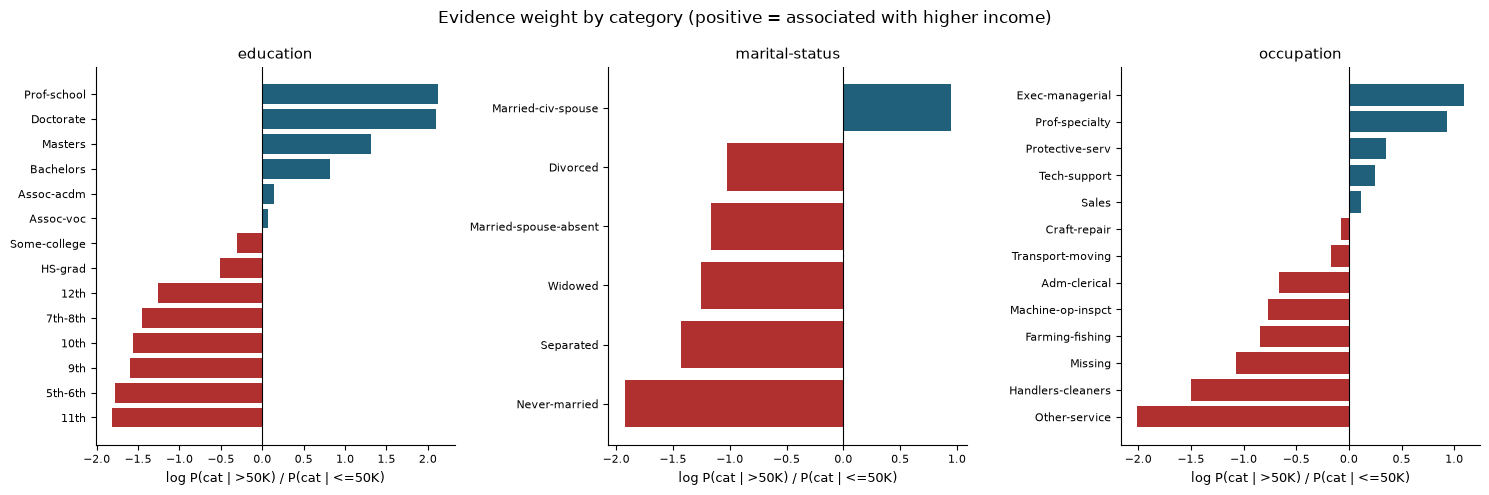

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, feature in zip(axes, ["education", "marital-status", "occupation"]):
    tab = evidence_weights(nb_adult, feature, VOCAB[CAT.index(feature)],
                           min_share=0.01).sort_values("evidence weight")
    colors = ["#b03030" if w < 0 else "#20607a" for w in tab["evidence weight"]]
    ax.barh(tab.index, tab["evidence weight"], color=colors)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(feature, fontsize=11)
    ax.set_xlabel("log P(cat | >50K) / P(cat | <=50K)", fontsize=9)
    ax.tick_params(labelsize=8)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Evidence weight by category (positive = associated with higher income)",
             fontsize=12)
plt.tight_layout()
plt.show()

### What to look for, and how to be careful about it

Read the education panel first: the ordering will be close to monotone in credential
level, which is the single most robust finding in stratification research and a good sign
the model is picking up something real rather than noise.

Then read `marital-status`, and be careful. `Married-civ-spouse` will almost certainly
carry a large positive weight. It is tempting to narrate this as "marriage raises income."
At least four mechanisms are tangled in that one coefficient, and this model cannot
separate them:

1. **Selection** — higher earners are more likely to marry in the first place.
2. **Measurement** — the income variable interacts with household and filing structure.
3. **Age confounding** — married people are older, and earnings rise with age.
4. **Gendered specialisation** within households.

A Naive Bayes weight is a *marginal* association: it compares married to unmarried people
without holding age, education or occupation constant. This is exactly the point at which
a classifier stops being able to answer the question you want answered and you need a
research design instead.

## 3.8 Auditing the independence assumption

We have been assuming the predictors are conditionally independent given income. Let's
measure how false that is, using **Cramér's V** — a chi-squared-based association measure
for two categorical variables, scaled to [0, 1].

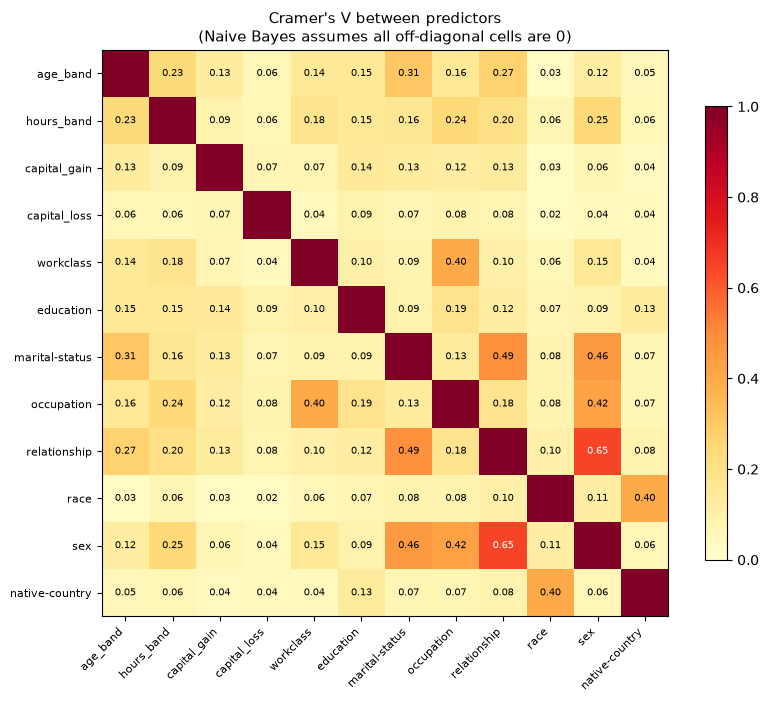

most strongly associated pairs:
relationship    sex               0.647
marital-status  relationship      0.488
                sex               0.459
occupation      sex               0.424
race            native-country    0.402
workclass       occupation        0.400
age_band        marital-status    0.307
                relationship      0.270


In [31]:
from scipy.stats import chi2_contingency

def cramers_v(a, b):
    table = pd.crosstab(a, b)
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()
    r, k = table.shape
    return np.sqrt((chi2 / n) / max(1, min(r - 1, k - 1)))


V = pd.DataFrame(
    [[cramers_v(Xc[a], Xc[b]) for b in CAT] for a in CAT],
    index=CAT, columns=CAT)

fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(V.to_numpy(), cmap="YlOrRd", vmin=0, vmax=1)
ax.set_xticks(range(len(CAT)), CAT, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(CAT)), CAT, fontsize=8)
for i in range(len(CAT)):
    for j in range(len(CAT)):
        if i != j:
            ax.text(j, i, f"{V.iat[i, j]:.2f}", ha="center", va="center", fontsize=7,
                    color="black" if V.iat[i, j] < 0.6 else "white")
ax.set_title("Cramer's V between predictors\n(Naive Bayes assumes all off-diagonal cells are 0)",
             fontsize=11)
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

pairs = (V.where(np.triu(np.ones(V.shape), k=1).astype(bool))
          .stack().sort_values(ascending=False))
print("most strongly associated pairs:")
print(pairs.head(8).round(3).to_string())

Naive Bayes assumes every off-diagonal cell in that matrix is zero. It is not. The
`marital-status`/`relationship`/`sex` cluster should stand out sharply — `relationship`
has values like `Husband` and `Wife`, which encode marital status and sex *by
construction*, so the model is counting the same fact up to three times.

Yet the AUC above was respectable. That is the enduring puzzle about Naive Bayes, and the
resolution is worth stating precisely: violated independence corrupts the *probabilities*
much more than it corrupts the *ranking*. Double-counted evidence pushes posteriors toward
0 and 1, but it tends to push them in the same direction they were already going, so the
ordering of cases — and hence AUC, and hence the argmax decision — survives.

### Does dropping the redundancy help?

In [32]:
CAT_TRIMMED = [c for c in CAT if c != "relationship"]
Xt = pd.DataFrame(
    OrdinalEncoder(categories=[sorted(Xc[c].unique().tolist()) for c in CAT_TRIMMED])
    .fit_transform(Xc[CAT_TRIMMED]), columns=CAT_TRIMMED, index=Xc.index)

nb_trim = CategoricalNB(alpha=1.0).fit(Xt.iloc[idx_train], y_train)
prob_trim = nb_trim.predict_proba(Xt.iloc[idx_test])[:, 1]

print(f"with 'relationship':     AUC {roc_auc_score(y_test, prob_nb):.4f}")
print(f"without 'relationship':  AUC {roc_auc_score(y_test, prob_trim):.4f}")
print("\nCompare the two. If dropping a redundant feature barely moves AUC but the")
print("feature had a high Cramer's V with others, that is the effect described above:")
print("the ranking was robust to the violation even though the probabilities were not.")

with 'relationship':     AUC 0.8902
without 'relationship':  AUC 0.8893

Compare the two. If dropping a redundant feature barely moves AUC but the
feature had a high Cramer's V with others, that is the effect described above:
the ranking was robust to the violation even though the probabilities were not.


## 3.9 Calibration: are the probabilities trustworthy?

In Example 2 we predicted 0.85 for a profile whose true rate was 0.50. Let's measure that
failure mode properly here. Group the test set by predicted probability and compare the
average prediction in each bucket to the actual rate. A well-calibrated model puts those
two numbers close together.

In [33]:
cal = pd.DataFrame({"p": prob_nb, "y": y_test.to_numpy()})
cal["bucket"] = pd.cut(cal["p"], np.linspace(0, 1, 11))

table = (cal.groupby("bucket", observed=True)
            .agg(n=("y", "size"), mean_predicted=("p", "mean"), actual_rate=("y", "mean")))
table["gap"] = table["mean_predicted"] - table["actual_rate"]
print(table.round(3))

               n  mean_predicted  actual_rate    gap
bucket                                              
(0.0, 0.1]  6544           0.011        0.038 -0.027
(0.1, 0.2]   559           0.143        0.191 -0.048
(0.2, 0.3]   461           0.250        0.245  0.005
(0.3, 0.4]   369           0.358        0.247  0.111
(0.4, 0.5]   369           0.452        0.276  0.176
(0.5, 0.6]   349           0.550        0.304  0.246
(0.6, 0.7]   515           0.649        0.390  0.258
(0.7, 0.8]   504           0.748        0.423  0.326
(0.8, 0.9]   703           0.854        0.501  0.354
(0.9, 1.0]  1838           0.967        0.754  0.213


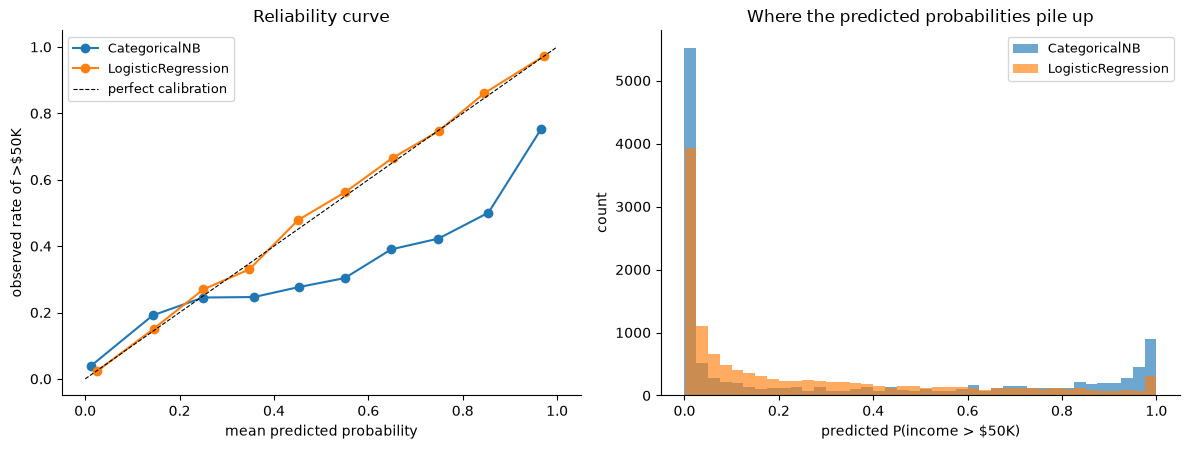

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))

for label, probs in [("CategoricalNB", prob_nb), ("LogisticRegression", prob_lr)]:
    c = pd.DataFrame({"p": probs, "y": y_test.to_numpy()})
    c["bucket"] = pd.cut(c["p"], np.linspace(0, 1, 11))
    g = c.groupby("bucket", observed=True).agg(pred=("p", "mean"), actual=("y", "mean"))
    axes[0].plot(g["pred"], g["actual"], "o-", lw=1.5, label=label)

axes[0].plot([0, 1], [0, 1], "k--", lw=0.8, label="perfect calibration")
axes[0].set_xlabel("mean predicted probability")
axes[0].set_ylabel("observed rate of >$50K")
axes[0].set_title("Reliability curve")
axes[0].legend(fontsize=9)

axes[1].hist(prob_nb, bins=40, alpha=0.65, label="CategoricalNB")
axes[1].hist(prob_lr, bins=40, alpha=0.65, label="LogisticRegression")
axes[1].set_xlabel("predicted P(income > $50K)")
axes[1].set_ylabel("count")
axes[1].set_title("Where the predicted probabilities pile up")
axes[1].legend(fontsize=9)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

Look at the right-hand histogram. Naive Bayes tends to pile predictions up against 0 and
1, while logistic regression spreads them through the middle. That is the double-counting
of correlated evidence, visible directly.

**The practical rule:** use Naive Bayes probabilities to *rank* cases, not as calibrated
estimates of risk. 

## 3.10 Who does the model fail?

An aggregate metric hides distributional damage. A model can look fine overall and be
systematically worse for a subgroup. Since the features here include `sex` and `race`,
we can and should check.

This is a descriptive audit, not a fairness verdict — "fairness" has several mutually
incompatible formal definitions, and choosing among them is an ethical and political
question, not something a notebook settles.

In [36]:
def subgroup_report(attribute):
    frame = pd.DataFrame({
        "group": d.iloc[idx_test][attribute].to_numpy(),
        "y": y_test.to_numpy(),
        "pred": pred_nb,
    })
    rows = []
    for name, g in frame.groupby("group"):
        pos, neg = g[g["y"] == 1], g[g["y"] == 0]
        rows.append({
            attribute: name,
            "n": len(g),
            "true rate >50K": g["y"].mean(),
            "predicted rate": g["pred"].mean(),
            "recall": pos["pred"].mean() if len(pos) else np.nan,
            "FPR": neg["pred"].mean() if len(neg) else np.nan,
            "accuracy": (g["y"] == g["pred"]).mean(),
        })
    return pd.DataFrame(rows).set_index(attribute).sort_values("n", ascending=False)


print("=== by sex " + "=" * 50)
print(subgroup_report("sex").round(3))
print("\n=== by race " + "=" * 49)
print(subgroup_report("race").round(3))

=== by sex ==================================================
           n  true rate >50K  predicted rate  recall    FPR  accuracy
sex                                                                  
Male    8187           0.302           0.446   0.837  0.277     0.757
Female  4024           0.113           0.064   0.422  0.018     0.918

=== by race =================================================
                        n  true rate >50K  predicted rate  recall    FPR  accuracy
race                                                                              
White               10385           0.254           0.347   0.784  0.198     0.797
Black                1208           0.126           0.108   0.592  0.038     0.916
Asian-Pac-Islander    393           0.260           0.364   0.814  0.206     0.799
Amer-Indian-Eskimo    118           0.153           0.186   0.667  0.100     0.864
Other                 107           0.103           0.084   0.273  0.062     0.869


Compare the `recall` column across groups. Recall is the share of genuinely high-earning
people the model finds. If it is markedly lower for one group, the model is
disproportionately failing to identify high earners in that group — and if such a model
were used to target a programme or allocate a resource, that gap would become a
distributional harm.

Two mechanisms usually drive this, and they call for different responses:

- **Base rates differ across groups.** Naive Bayes multiplies in `P(sex | class)`, so a
  group with a lower observed rate of high earnings gets pushed toward the low-income
  prediction for that reason alone.
- **Sample size differs.** Smaller groups have noisier likelihood estimates, and Laplace
  smoothing pulls them harder toward uniform (adding 1 to a denominator of 200 matters
  more than adding 1 to a denominator of 20,000).

Worth trying as an exercise: refit without `sex` and `race` and see what happens to the
subgroup gaps. The result is usually instructive — removing a protected attribute often
does **not** close the gap, because correlated features such as `occupation` and
`relationship` carry the same information. "Fairness through unawareness" mostly doesn't
work, and this dataset demonstrates it cleanly.

## 3.11 What would we conclude?

Stated as a researcher would state it:

> Using twelve demographic and employment characteristics from the 1994 CPS, a Naive
> Bayes classifier separates individuals earning above and below \$50,000 substantially
> better than chance, despite strongly violated
> independence assumptions among its predictors. Educational credentials and occupational
> category carry the largest evidence weights, in an ordering consistent with
> stratification research. The model's probability estimates are poorly calibrated,
> concentrating near 0 and 1; they are usable for ranking but not as risk estimates.
> Recall varies across sex and racial groups, reflecting differences in both base rates
> and estimation precision.

And what it does **not** license:

- No causal claim. Nothing here establishes that a credential *causes* higher earnings.
- No claim about today. These are 1994 associations at a 1994 dollar threshold.
- No claim about the population without weights. `fnlwgt` exists for a reason and we
  ignored it, as nearly everyone using this dataset does. A published analysis should not.

# Closing: a checklist

**Choosing a variant**

- All features categorical → `CategoricalNB`
- All continuous and plausibly normal within class → `GaussianNB`
- Counts (text, events) → `MultinomialNB`; binary indicators → `BernoulliNB`
- Mixed types → bin the continuous features, or combine two models as in Section 3.6

**Costly Mistakes**

1. Integer-encoding categories and then using `GaussianNB`. It runs. It is wrong.
2. Forgetting that `alpha=1.0` is the default, then wondering why the code disagrees with
   your hand calculation.
3. Reporting accuracy on imbalanced data. Always give the majority-class baseline beside it.
4. Treating Naive Bayes probabilities as calibrated risks. Rank with them; don't quote them.
5. Reading a likelihood ratio as a causal effect. It is a marginal association with
   nothing held constant.
6. Including two features that encode the same thing (`education` and `education-num`).
   Multiplying likelihoods counts that evidence twice.
7. Fitting any outcome-dependent transformation before the train/test split.
